# Credit Risk Early Warning System (EWS) Project - Deep Learning part

## Preamble
The main task of the project is to be able to create an Early Warning System for banks to be able to use to predict whether a specific country's credit risk will go up, down, or stagnate in the coming 30-90 days. One of the main elements of this project is using Deep Learning (DL) models to carry out this prediction, and later comparing the results to more basic Machine Learning (ML) models' results. This notebook will comprise of the DL part of the task.

## STEP 1 - ALIGNMENT

Since data was taken directly from Bloomberg, we have to ensure that the extracted xlsx file's format can be directly translated into a *pandas* dataframe, to make working with it much easier. This was done with specific functions tailor made for the Bloomberg export format to ensure data stability further down the line.

In [ ]:
import pandas as pd
import numpy as np

def create_master_dataframe(file_path):
    print("Reading mappings from bbg_data_raw...")

    # 1. Build the Ticker -> Country Mapping
    raw_mapping = pd.read_excel(file_path, sheet_name='bbg_data_raw', header=None)
    countries = raw_mapping.iloc[0, 1:].astype(str).str.strip().values

    ticker_to_country = {}
    for i in range(1, len(raw_mapping)):
        for j in range(1, len(raw_mapping.columns)):
            ticker = str(raw_mapping.iloc[i, j]).strip()
            country = countries[j-1]
            if ticker and ticker.lower() != 'nan':
                ticker_to_country[ticker] = country

    # NEW: Dictionary to catch Bloomberg's specific CDS abbreviations
    cds_abbrev_map = {
        'REPSOU': 'South Africa',
        'SAUDI': 'Saudi Arabia',
        'INDON': 'Indonesia',
        'MALAYS': 'Malaysia',
        'PHILIP': 'Philippines',
        'CZECH': 'Czech Rep.',
        'COLOM': 'Colombia',
        'PORTUG': 'Portugal',
        'US': 'United States',
        'SWISS': 'Switzerland',
        'UK': 'United Kingdom',
        'AUSTRAL': 'Australia',
        'CANPAC': 'Canada',
        'CHINAGOV': 'China'
    }

    # 2. Function to process and reshape wide Bloomberg Data Sheets
    def process_bbg_sheet(sheet_name, value_name):
        print(f"Processing sheet: {sheet_name}...")
        try:
            df = pd.read_excel(file_path, sheet_name=sheet_name, header=None)
        except ValueError:
            print(f"  -> Warning: Sheet '{sheet_name}' not found. Returning empty DataFrame.")
            return pd.DataFrame(columns=['Date', 'Country', value_name])

        # Identify the row with standard Bloomberg tags to locate the header boundary
        field_row_mask = df.apply(lambda x: x.astype(str).str.contains('PX_LAST|YLD_YTM_MID', na=False).any(), axis=1)

        if field_row_mask.any():
            field_row_idx = field_row_mask.idxmax()
            ticker_row_idx = field_row_idx - 1
        else:
            ticker_row_idx = 1
            field_row_idx = 2

        tickers = df.iloc[ticker_row_idx].astype(str).str.strip().values
        data = df.iloc[field_row_idx + 1:].reset_index(drop=True)

        dfs = []
        for col in range(1, len(df.columns), 2):
            ticker = tickers[col]
            if ticker.lower() == 'nan' or not ticker:
                continue

            # Extract the 2-column slice for this specific security
            temp = data.iloc[:, col:col+2].copy()
            temp.columns = ['Date', value_name]

            temp = temp.dropna(subset=['Date', value_name])
            temp['Date'] = pd.to_datetime(temp['Date'], errors='coerce')
            temp = temp.dropna(subset=['Date'])

            # ATTEMPT 1: Map using the raw_mapping sheet
            country = ticker_to_country.get(ticker)

            # ATTEMPT 2: Fallback to string matching (e.g., "BRAZIL" -> Brazil)
            if not country:
                for c in countries:
                    if str(c).upper() in ticker.upper():
                        country = c
                        break

            # ATTEMPT 3: NEW! Fallback to the abbreviation dictionary
            if not country:
                prefix = ticker.split()[0]  # Extracts the first word (e.g., "REPSOU")
                country = cds_abbrev_map.get(prefix)

            temp['Country'] = country if country else 'Unknown'
            dfs.append(temp[['Date', 'Country', value_name]])

        if dfs:
            return pd.concat(dfs, ignore_index=True)
        else:
            return pd.DataFrame(columns=['Date', 'Country', value_name])

    # 3. Process the three requested sheets
    df_cds = process_bbg_sheet('5y_CDS_values', 'CDS')
    df_yield = process_bbg_sheet('10y_yields_values', 'Yield')
    df_vol = process_bbg_sheet('fx_volatitilies_values', 'FX_Vol')

    # 4. Merge into a Master DataFrame
    print("Merging datasets into Master DataFrame...")

    df_cds = df_cds.drop_duplicates(subset=['Date', 'Country'])
    df_yield = df_yield.drop_duplicates(subset=['Date', 'Country'])
    df_vol = df_vol.drop_duplicates(subset=['Date', 'Country'])

    # Full outer join
    master_df = pd.merge(df_cds, df_yield, on=['Date', 'Country'], how='outer')
    master_df = pd.merge(master_df, df_vol, on=['Date', 'Country'], how='outer')

    # Sort for final output readability
    master_df = master_df.sort_values(by=['Country', 'Date']).reset_index(drop=True)

    return master_df

# --- Execution ---
if __name__ == "__main__":
    file_name = 'bbg_data_raw.xlsx'
    df_master = create_master_dataframe(file_name)

    print("\nMaster DataFrame Preview:")
    print(df_master.head(10))

    df_master.to_csv('bbg_master_clean.csv', index=False)
    print("\nFile saved successfully as 'bbg_master_clean.csv'")

## Imputation

In [ ]:
def impute_financial_data(df, features=['CDS', 'Yield', 'FX_Vol']):
    df = df.copy()

    resampled = []
    for country, group in df.groupby('Country'):
        group = group.set_index('Date').resample('D').asfreq()
        group['Country'] = country
        resampled.append(group)

    df = pd.concat(resampled).reset_index()

    df[features] = df.groupby('Country')[features].ffill()
    df[features] = df.groupby('Country')[features].bfill()

    return df

# --- Execution ---
clean_hf_df = impute_financial_data(df_master)

## S&P Credit Rating Targets

Parse the `credit_rating_changes_SP` sheet into a daily target DataFrame. Each rating change event is labeled as **1 (upgrade)**, **2 (downgrade)**, or **0 (no change)**.

In [ ]:
## S&P Credit Rating Target Construction

SP_SCALE = {
    'AAA': 22, 'AA+': 21, 'AA': 20, 'AA-': 19,
    'A+': 18,  'A': 17,   'A-': 16,
    'BBB+': 15,'BBB': 14, 'BBB-': 13,
    'BB+': 12, 'BB': 11,  'BB-': 10,
    'B+': 9,   'B': 8,    'B-': 7,
    'CCC+': 6, 'CCC': 5,  'CCC-': 4,
    'CC': 3,   'C': 2,    'D': 1
}

def parse_sp_ratings(file_path):
    df = pd.read_excel(file_path, sheet_name='credit_rating_changes_SP', header=None)

    records = []
    for col in range(0, df.shape[1], 2):
        country = str(df.iloc[0, col]).strip()
        if country in ('nan', 'NaT', ''):
            continue

        for row in range(3, df.shape[0]):
            raw_rating = str(df.iloc[row, col]).strip()
            raw_date   = df.iloc[row, col + 1]

            if raw_rating in ('nan', 'NaT', '') or pd.isnull(raw_date):
                continue

            clean_rating = raw_rating.rstrip('uU')
            date = pd.to_datetime(raw_date, errors='coerce')
            if pd.isnull(date) or clean_rating not in SP_SCALE:
                continue

            records.append({'Date': date, 'Country': country, 'Rating': clean_rating})

    long_df = pd.DataFrame(records).sort_values(['Country', 'Date']).reset_index(drop=True)
    long_df['Rating_Num'] = long_df['Rating'].map(SP_SCALE)

    long_df['Prev_Num'] = long_df.groupby('Country')['Rating_Num'].shift(1)
    long_df['Target_Class'] = np.where(
        long_df['Prev_Num'].isna(), 0,
        np.where(long_df['Rating_Num'] > long_df['Prev_Num'], 1,
        np.where(long_df['Rating_Num'] < long_df['Prev_Num'], 2,
        0))
    )

    return long_df[['Date', 'Country', 'Target_Class']].copy()

# --- Execution ---
clean_targets_df = parse_sp_ratings('bbg_data_with_functions.xlsx')

print('Target distribution:')
print(clean_targets_df['Target_Class'].value_counts())
print(clean_targets_df.head(10))

## Chronological Validation Split (to ensure we predict new data based on past data)

In [4]:
def chronological_split(df, target_df, test_ratio=0.2):
    """
    Splits the sequential features and tabular targets based on a chronological cutoff.
    """
    # Find the global cutoff date
    unique_dates = df['Date'].sort_values().unique()
    split_index = int(len(unique_dates) * (1 - test_ratio))
    cutoff_date = unique_dates[split_index]

    print(f"Splitting data chronologically at date: {pd.to_datetime(cutoff_date).date()}")

    # Split High-Frequency Data
    train_hf = df[df['Date'] <= cutoff_date].copy()
    test_hf = df[df['Date'] > cutoff_date].copy()

    # Split Targets (Assuming target_df has been similarly parsed to have 'Date' and 'Country')
    train_targets = target_df[target_df['Date'] <= cutoff_date].copy()
    test_targets = target_df[target_df['Date'] > cutoff_date].copy()

    return train_hf, test_hf, train_targets, test_targets

# --- Execution ---
# (Assuming 'clean_targets_df' was created similarly for your SP rating changes)
train_hf, test_hf, train_targets, test_targets = chronological_split(clean_hf_df, clean_targets_df, test_ratio=0.2)

# Now these subsets can be passed to the PyTorch Dataset class written in the previous response:
# train_dataset = CreditRiskTimeSeriesDataset(train_hf, train_targets, lookback=60, horizon=30)
# test_dataset = CreditRiskTimeSeriesDataset(test_hf, test_targets, lookback=60, horizon=30)

Splitting data chronologically at date: 2022-10-20


## Sequential Data Windowing and PyTorch Dataset

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler

class CreditRiskTimeSeriesDataset(Dataset):
    def __init__(self, df, target_df, lookback=60, horizon=30):
        """
        Args:
            df (pd.DataFrame): High-frequency data, sorted by Date.
                               Must contain ['Date', 'Country', 'CDS', 'Yield', 'FX_Vol']
            target_df (pd.DataFrame): The credit rating changes aligned by Date and Country.
                                      Contains ['Date', 'Country', 'Target_Class']
                                      where Target_Class is 0 (No Change), 1 (Upgrade), 2 (Downgrade).
            lookback (int): Number of days in the past to use for the LSTM sequence.
            horizon (int): Number of days in the future to predict (e.g., 30 or 90).
        """
        self.lookback = lookback
        self.horizon = horizon
        self.features = ['CDS', 'Yield', 'FX_Vol']

        # 1. Normalize the continuous features
        self.scaler = StandardScaler()
        df[self.features] = self.scaler.fit_transform(df[self.features])

        self.x_data = []
        self.y_data = []

        # 2. Group by Country to prevent cross-country data leakage in sequences
        grouped = df.groupby('Country')

        for country, group in grouped:
            group = group.sort_values('Date').reset_index(drop=True)
            # Align targets for this specific country
            country_targets = target_df[target_df['Country'] == country].sort_values('Date').reset_index(drop=True)

            # Merge to ensure dates line up perfectly
            merged = pd.merge(group, country_targets, on='Date', how='left')

            # Forward fill targets if necessary, or keep as is if daily labels are provided
            values = merged[self.features].values
            targets = merged['Target_Class'].values

            # 3. Create Sliding Windows
            # We iterate up to len(values) - lookback - horizon to ensure we have a future target
            for i in range(len(values) - self.lookback - self.horizon):
                # The input sequence: from day `i` to day `i + lookback`
                seq_x = values[i : i + self.lookback]

                # The target: `horizon` days AFTER the end of the lookback window
                target_idx = i + self.lookback + self.horizon
                seq_y = targets[target_idx]

                # Only append if we have a valid target (handling NaNs if present)
                if not np.isnan(seq_y):
                    self.x_data.append(seq_x)
                    self.y_data.append(seq_y)

        self.x_data = torch.tensor(np.array(self.x_data), dtype=torch.float32)
        self.y_data = torch.tensor(np.array(self.y_data), dtype=torch.long)

    def __len__(self):
        return len(self.x_data)

    def __getitem__(self, idx):
        return self.x_data[idx], self.y_data[idx]

# --- Usage Example ---
# train_dataset = CreditRiskTimeSeriesDataset(clean_hf_df, clean_targets_df, lookback=60, horizon=30)
# train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, drop_last=True)

In [ ]:
import sys
print(sys.executable)

## Mitigating Strong Class Imbalance

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
from sklearn.utils.class_weight import compute_class_weight

def get_class_weights(y_train):
    """
    Standard sklearn balanced weights: total / (n_classes * count_per_class).
    Gives ~17x weight to minority classes — the correct statistical correction.
    Combined with gamma=1.5 (not 2.0) this avoids both extremes:
      - gamma=2.0 + balanced → predicted upgrade/downgrade for everything
      - sqrt weights + gamma=1.0 → predicted no-change for everything
    """
    classes = np.unique(y_train)
    weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
    return torch.tensor(weights, dtype=torch.float32)

class FocalLoss(nn.Module):
    def __init__(self, weight=None, gamma=2.0, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.weight    = weight
        self.gamma     = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss    = F.cross_entropy(inputs, targets, weight=self.weight, reduction='none')
        pt         = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        return focal_loss



Low-Frequency Data Loading

The three macro indicators (CPI inflation, FX reserves, central bank policy rate) are stored in
the same Bloomberg wide format in `bbg_data_raw.xlsx`. Unlike the HF data, inflation and FX
reserves are monthly; the policy rate is daily but changes infrequently (step function).

All three are parsed into long format and then forward-filled onto the HF daily date grid so
that each row in the master dataset has a current macro snapshot.

In [ ]:
def create_lf_dataframe(file_path):
    """
    Parses low-frequency macro sheets: inflation_values, fx_reserves_values,
    central_back_policy_rate_values.

    fx_reserves and policy_rate have country names in row 0.
    inflation has a note in row 0, so we borrow the country order from fx_reserves.
    """

    def parse_country_header_sheet(sheet_name, value_name):
        """For sheets where row 0 contains: [note/label, Country, None, Country, None, ...]"""
        df = pd.read_excel(file_path, sheet_name=sheet_name, header=None)
        country_entries = df.iloc[0, 1:].astype(str).str.strip().values
        # Countries sit at every even position (0, 2, 4, ...) of this slice
        countries = [c for i, c in enumerate(country_entries) if i % 2 == 0 and c not in ('nan', '')]

        dfs = []
        for i, country in enumerate(countries):
            col = 1 + i * 2  # actual column index in the sheet
            temp = df.iloc[3:, col:col + 2].copy()
            temp.columns = ['Date', value_name]
            temp = temp.dropna(subset=['Date', value_name])
            temp['Date'] = pd.to_datetime(temp['Date'], errors='coerce')
            temp[value_name] = pd.to_numeric(temp[value_name], errors='coerce')
            temp = temp.dropna()
            temp['Country'] = country
            dfs.append(temp[['Date', 'Country', value_name]])

        return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame(columns=['Date', 'Country', value_name])

    def parse_inflation_sheet(file_path, value_name='Inflation'):
        """
        Inflation sheet has a note in row 0 instead of country names.
        We assume the same 30-country column order as fx_reserves_values.
        """
        df_inf = pd.read_excel(file_path, sheet_name='inflation_values', header=None)
        df_ref = pd.read_excel(file_path, sheet_name='fx_reserves_values', header=None)

        country_entries = df_ref.iloc[0, 1:].astype(str).str.strip().values
        countries = [c for i, c in enumerate(country_entries) if i % 2 == 0 and c not in ('nan', '')]

        dfs = []
        for i, country in enumerate(countries):
            col = 1 + i * 2
            if col >= df_inf.shape[1]:
                break
            temp = df_inf.iloc[3:, col:col + 2].copy()
            temp.columns = ['Date', value_name]
            temp = temp.dropna(subset=['Date', value_name])
            temp['Date'] = pd.to_datetime(temp['Date'], errors='coerce')
            temp[value_name] = pd.to_numeric(temp[value_name], errors='coerce')
            temp = temp.dropna()
            temp['Country'] = country
            dfs.append(temp[['Date', 'Country', value_name]])

        return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame(columns=['Date', 'Country', value_name])

    df_inflation = parse_inflation_sheet(file_path)
    df_fx_res    = parse_country_header_sheet('fx_reserves_values', 'FX_Reserves')
    df_rate      = parse_country_header_sheet('central_back_policy_rate_values', 'Policy_Rate')

    lf = pd.merge(df_inflation, df_fx_res, on=['Date', 'Country'], how='outer')
    lf = pd.merge(lf, df_rate,            on=['Date', 'Country'], how='outer')
    lf = lf.sort_values(['Country', 'Date']).reset_index(drop=True)
    return lf


def align_lf_to_daily(hf_df, lf_df, lf_features=['Inflation', 'FX_Reserves', 'Policy_Rate']):
    """
    Forward-fills monthly/step LF readings onto the HF daily date grid.
    Each daily row gets the most recently available macro reading for that country.
    """
    merged = pd.merge(hf_df[['Date', 'Country']], lf_df, on=['Date', 'Country'], how='left')
    merged = merged.sort_values(['Country', 'Date'])
    merged[lf_features] = merged.groupby('Country')[lf_features].ffill()
    merged[lf_features] = merged.groupby('Country')[lf_features].bfill()
    return merged.reset_index(drop=True)


# --- Execution ---
lf_raw       = create_lf_dataframe('bbg_data_raw.xlsx')
clean_lf_df  = align_lf_to_daily(clean_hf_df, lf_raw)

print("LF DataFrame shape:", clean_lf_df.shape)
print(clean_lf_df.head(5))

## Combined Dataset (HF + LF)

Each sample returns a tuple of `(hf_sequence, lf_snapshot, target_class)` so that both encoders can be trained jointly.

In [ ]:
class CreditRiskFusionDataset(Dataset):
    def __init__(self, hf_df, lf_df, target_df, lookback=60, horizon_start=30, horizon_end=90,
                 hf_scaler=None, lf_scaler=None):
        self.lookback = lookback
        self.horizon_start = horizon_start
        self.horizon_end = horizon_end
        hf_features   = ['CDS', 'Yield', 'FX_Vol']
        lf_features   = ['Inflation', 'FX_Reserves', 'Policy_Rate']

        hf_df = hf_df.copy()
        lf_df = lf_df.copy()

        # Fill any residual NaN with per-feature median BEFORE scaling
        # (StandardScaler propagates NaN → NaN loss in training)
        hf_df[hf_features] = hf_df[hf_features].fillna(hf_df[hf_features].median())

        if hf_scaler is None:
            hf_scaler = StandardScaler()
            hf_df[hf_features] = hf_scaler.fit_transform(hf_df[hf_features])
        else:
            hf_df[hf_features] = hf_scaler.transform(hf_df[hf_features])

        if lf_scaler is None:
            lf_scaler = StandardScaler()
            lf_df[lf_features] = lf_scaler.fit_transform(lf_df[lf_features].fillna(0))
        else:
            lf_df[lf_features] = lf_scaler.transform(lf_df[lf_features].fillna(0))

        self.hf_scaler = hf_scaler
        self.lf_scaler = lf_scaler

        x_seq_list, x_tab_list, y_list = [], [], []

        for country, hf_group in hf_df.groupby('Country'):
            hf_group = hf_group.sort_values('Date').reset_index(drop=True)
            lf_group = lf_df[lf_df['Country'] == country].sort_values('Date')
            ct       = target_df[target_df['Country'] == country].sort_values('Date')

            merged = pd.merge(hf_group, ct, on='Date', how='left')
            merged['Target_Class'] = merged['Target_Class'].fillna(0)

            hf_vals = merged[hf_features].values
            targets = merged['Target_Class'].values
            dates   = merged['Date'].values

            for i in range(len(hf_vals) - lookback - horizon_end):

                start_idx = i + lookback + horizon_start
                end_idx   = i + lookback + horizon_end
                window_targets = targets[start_idx : end_idx]

                if 2 in window_targets:
                    window_label = 2
                elif 1 in window_targets:
                    window_label = 1
                else:
                    window_label = 0

                current_date = dates[i + lookback - 1]
                lf_snap = lf_group[lf_group['Date'] <= current_date]

                tab_x = lf_snap.iloc[-1][lf_features].values.astype(float) if not lf_snap.empty else np.zeros(len(lf_features))
                tab_x = np.nan_to_num(tab_x)

                # Safety net: replace any surviving NaN in the HF sequence with 0
                seq = np.nan_to_num(hf_vals[i:i + lookback], nan=0.0)
                x_seq_list.append(seq)
                x_tab_list.append(tab_x)
                y_list.append(window_label)

        self.x_seq  = torch.tensor(np.array(x_seq_list), dtype=torch.float32)
        self.x_tab  = torch.tensor(np.array(x_tab_list), dtype=torch.float32)
        self.y_data = torch.tensor(np.array(y_list),     dtype=torch.long)

    def __len__(self):  return len(self.y_data)
    def __getitem__(self, idx): return self.x_seq[idx], self.x_tab[idx], self.y_data[idx]


## LSTM Encoder, MLP Encoder & Late Fusion Model

In [ ]:
class LSTMEncoder(nn.Module):
    def __init__(self, input_size=3, hidden_size=64, num_layers=2, dropout=0.3):
        super().__init__()
        self.lstm    = nn.LSTM(input_size, hidden_size, num_layers=num_layers,
                                batch_first=True, dropout=dropout)
        self.out_dim = hidden_size

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        return h_n[-1]


class MLPEncoder(nn.Module):
    def __init__(self, input_size=3, hidden_size=32, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU()
        )
        self.out_dim = hidden_size

    def forward(self, x):
        return self.net(x)


class LateFusionModel(nn.Module):
    def __init__(self, hf_input=3, lf_input=3, lstm_hidden=64,
                 mlp_hidden=32, num_classes=3, dropout=0.3):
        super().__init__()
        self.lstm_encoder = LSTMEncoder(hf_input, lstm_hidden, dropout=dropout)
        self.mlp_encoder  = MLPEncoder(lf_input,  mlp_hidden,  dropout=dropout)
        self.classifier   = nn.Sequential(
            nn.Linear(lstm_hidden + mlp_hidden, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, x_seq, x_tab):
        return self.classifier(torch.cat([self.lstm_encoder(x_seq),
                                          self.mlp_encoder(x_tab)], dim=1))


## Training Loop

In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimizer,
                num_epochs=30, device='cpu'):
    model.to(device)
    best_val_loss = float('inf')

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        for x_seq, x_tab, y in train_loader:
            x_seq, x_tab, y = x_seq.to(device), x_tab.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x_seq, x_tab), y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for x_seq, x_tab, y in val_loader:
                x_seq, x_tab, y = x_seq.to(device), x_tab.to(device), y.to(device)
                val_loss += criterion(model(x_seq, x_tab), y).item()

        train_loss /= len(train_loader)
        val_loss   /= len(val_loader)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), 'best_model.pt')

        if (epoch + 1) % 5 == 0:
            print(f"Epoch {epoch+1:>3}/{num_epochs} | "
                  f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    print(f"\nBest Val Loss: {best_val_loss:.4f}")
    return model


In [ ]:
from tqdm import tqdm
import torch

def train_model(model, train_loader, val_loader, criterion, optimizer,
                num_epochs=50, device='cpu', patience=5):
    model.to(device)
    best_val_loss    = float('inf')
    epochs_no_improve = 0

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        train_loop = tqdm(train_loader, desc=f"Epoch {epoch+1:>2}/{num_epochs} [Train]", leave=False)

        for x_seq, x_tab, y in train_loop:
            x_seq, x_tab, y = x_seq.to(device), x_tab.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x_seq, x_tab), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            train_loss += loss.item()
            train_loop.set_postfix(loss=loss.item())

        model.eval()
        val_loss = 0.0
        val_loop = tqdm(val_loader, desc=f"Epoch {epoch+1:>2}/{num_epochs} [Valid]", leave=False)
        with torch.no_grad():
            for x_seq, x_tab, y in val_loop:
                x_seq, x_tab, y = x_seq.to(device), x_tab.to(device), y.to(device)
                val_loss += criterion(model(x_seq, x_tab), y).item()

        train_loss /= len(train_loader)
        val_loss   /= len(val_loader)

        improved = val_loss < best_val_loss
        if improved:
            best_val_loss    = val_loss
            epochs_no_improve = 0
            torch.save(model.state_dict(), 'best_model.pt')
        else:
            epochs_no_improve += 1

        tag = "  ← best" if improved else f"  (no improvement {epochs_no_improve}/{patience})"
        print(f"Epoch {epoch+1:>2}/{num_epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}{tag}")

        if epochs_no_improve >= patience:
            print(f"\nEarly stopping at epoch {epoch+1}.")
            break

    print(f"\nBest Val Loss: {best_val_loss:.4f}")
    return model


## Setup & Run Training

In [13]:
device = 'mps' if torch.backends.mps.is_available() else 'cpu'
print(f'Using device: {device}')

train_dataset = CreditRiskFusionDataset(train_hf, clean_lf_df, train_targets,
                                         lookback=60, horizon_start=30, horizon_end=90)
test_dataset  = CreditRiskFusionDataset(test_hf,  clean_lf_df, test_targets,
                                         lookback=60, horizon_start=30, horizon_end=90,
                                         hf_scaler=train_dataset.hf_scaler,
                                         lf_scaler=train_dataset.lf_scaler)

print(f'Train samples: {len(train_dataset)} | Test samples: {len(test_dataset)}')
print(f'Class distribution (train): {train_dataset.y_data.bincount()}')

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True,  drop_last=True)
test_loader  = DataLoader(test_dataset,  batch_size=128, shuffle=False, drop_last=False)

weights   = get_class_weights(train_dataset.y_data.numpy())
print(f'Class weights: {weights.numpy().round(2)}')  # should be [~0.35, ~17, ~16]

# gamma=1.5: middle ground between 2.0 (over-predicted minority) and 1.0 (over-predicted majority)
criterion = FocalLoss(weight=weights.to(device), gamma=1.5)

model     = LateFusionModel(hf_input=3, lf_input=3, lstm_hidden=64, mlp_hidden=32, num_classes=3)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

model = train_model(model, train_loader, test_loader, criterion, optimizer,
                    num_epochs=50, device=device, patience=5)


Using device: mps
Train samples: 135780 | Test samples: 30540
Class distribution (train): tensor([130253,   2703,   2824])
Class weights: [ 0.35 16.74 16.03]


Epoch  1/50 | Train Loss: 0.5589 | Val Loss: 0.8657  ← best


Epoch  2/50 | Train Loss: 0.4579 | Val Loss: 1.4511  (no improvement 1/5)


Epoch  3/50 | Train Loss: 0.4104 | Val Loss: 1.3533  (no improvement 2/5)


Epoch  4/50 | Train Loss: 0.3664 | Val Loss: 1.7975  (no improvement 3/5)


Epoch  5/50 | Train Loss: 0.3580 | Val Loss: 1.6962  (no improvement 4/5)


Epoch  6/50 | Train Loss: 0.3227 | Val Loss: 2.0034  (no improvement 5/5)

Early stopping at epoch 6.

Best Val Loss: 0.8657


## Evaluation Metrics

               precision    recall  f1-score   support

No Change (0)       1.00      0.03      0.06     29595
  Upgrade (1)       0.02      0.51      0.04       825
Downgrade (2)       0.01      0.50      0.01       120

     accuracy                           0.04     30540
    macro avg       0.34      0.35      0.04     30540
 weighted avg       0.97      0.04      0.06     30540



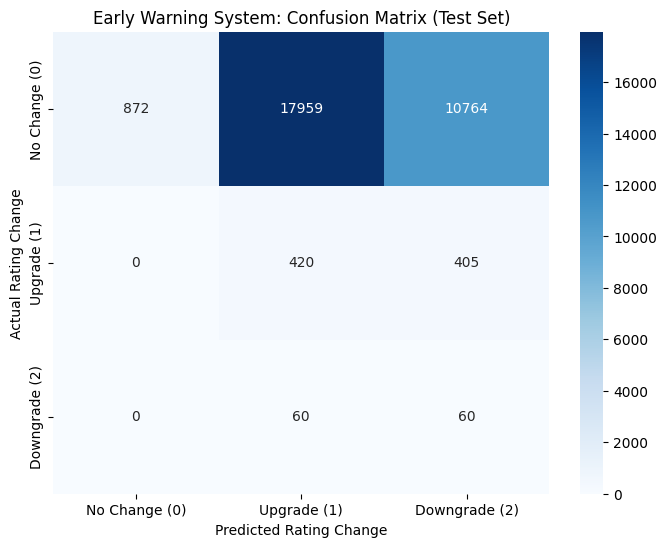

In [14]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

def evaluate_best_model(model, test_loader, device):
    # load best weights saved during training
    model.load_state_dict(torch.load('best_model.pt', map_location=device, weights_only=True))
    model.eval()
    all_preds = []
    all_targets = []
    with torch.no_grad():
        for x_seq, x_tab, y in test_loader:
            x_seq, x_tab, y = x_seq.to(device), x_tab.to(device), y.to(device)
            # raw logits from late fusion
            logits = model(x_seq, x_tab)
            # predictions
            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(y.cpu().numpy())

    # classification report
    target_names = ['No Change (0)', 'Upgrade (1)', 'Downgrade (2)']
    print(classification_report(all_targets, all_preds, target_names=target_names, zero_division=0))

    # confusion matrix
    cm = confusion_matrix(all_targets, all_preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=target_names, yticklabels=target_names)
    plt.ylabel('Actual Rating Change')
    plt.xlabel('Predicted Rating Change')
    plt.title('Early Warning System: Confusion Matrix (Test Set)')
    plt.show()

evaluate_best_model(model, test_loader, device=device)